# 01 · Data and Target — shared notebook

**PA04 · Guimarães (City A) vs Viana do Castelo (City B) · T4 Humid vs Dry Regime**
Business scenario: *Textile Storage Facility* — *How do humid and dry regimes differ between candidate warehouse locations?*

This is the **shared** first notebook of the project. It is run once, by either student, and its outputs are the common input of every later notebook:

| Notebook | Owner | Content |
|---|---|---|
| **01_data_and_target** (this one) | both | raw data → clean streams → warm-up → frozen τ_H → target T4 |
| 02_profile_guimaraes / 03_profile_viana_do_castelo | Student A / Student B | stream characterisation of the primary city (Ch. 9) |
| 04_experiment_and_comparison | both | Representations A/B, 5 models, prequential evaluation, city comparison |

**Steps in this notebook** (handbook chapter in brackets):

1. Setup and package versions (Ch. 12.9)
2. Assignment card and shared protocol (Ch. 3.1, 19)
3. Raw data snapshots — collect once, replay many times (Ch. 15)
4. Chronology and timezone (Ch. 12.1)
5. Data quality checks — flag, never silently delete (Ch. 9, 18)
6. Descriptive statistics (Ch. 9.2)
7. Common timeline and warm-up (Ch. 12.2)
8. Pooled warm-up threshold τ_H — estimate once, freeze (Ch. 6, 12.3–12.4)
9. Target T4 and the leakage rule (Ch. 6, 7)
10. Class distribution (Ch. 9.4, 11.1)
11. Protocol checks — automated temporal-alignment checklist (Ch. 7.1)
12. Save processed streams and the frozen configuration (Ch. 15.2)

> **Workflow rule:** collect once → save raw → prepare → replay as a stream.
> Later notebooks must **read** the files saved in step 12 and must **not** recompute τ_H.

> **AI policy (Ch. 16):** cells marked *📝 For the report* are for your own interpretation. Write them yourselves.

## 1. Setup and package versions

**Requirement (Ch. 12.9, 15):** record the package versions, random seed and historical period.
Environment: the project `.venv` (kernel *Python (dsm_asnm1)*), installed from `requirements.txt`.

In [1]:
import json
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from utils import ROOT, load_config, download_weather, save_raw_snapshot, load_raw_snapshot

pd.set_option("display.max_columns", 50)

VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
}
VERSIONS

{'python': '3.11.14',
 'pandas': '2.3.3',
 'numpy': '2.4.6',
 'matplotlib': '3.11.2'}

## 2. Assignment card and shared protocol

**Requirement (Ch. 3.1):** both cities must use the *same* target definition, threshold policy, warm-up rule, chronological protocol and metrics.
So every setting is defined **once**, in `config.yaml`, and is never set separately per city.

| Item | Value | `config.yaml` |
|---|---|---|
| Assignment | PA04, Textile Storage Facility | `project` |
| City A / City B | Guimarães / Viana do Castelo | `cities` |
| Target | **T4**: τ_H = Q0.50(H) from pooled warm-up; y = 1 if H_t ≥ τ_H | `target` |
| Historical period | 2023-01-01 to 2025-12-31 (3 years, hourly) | `data` |
| Warm-up | 2023-01-01 to 2023-12-31 (first full year, not scored) | `experiment` |
| Evaluation stream | 2024-01-01 to 2025-12-31 (2 years) | `experiment` |
| Random seed | 42 | `experiment` |

In [2]:
config = load_config()
data_cfg, storage_cfg = config["data"], config["storage"]
target_cfg, exp_cfg = config["target"], config["experiment"]

# --- Assignment card ---------------------------------------------------------------
ASSIGNMENT_CODE = config["project"]["assignment"]   # "PA04"
BUSINESS_SCENARIO = "Textile Storage Facility"
BUSINESS_QUESTION = "How do humid and dry regimes differ between candidate warehouse locations?"
TARGET_CODE = config["project"]["target"]           # "T4"
TARGET_NAME = target_cfg["name"]
TARGET_SOURCE = target_cfg["source_variable"]       # H_t
TARGET_QUANTILE = float(target_cfg["quantile"])     # 0.50, fixed by the handbook for T4
assert TARGET_CODE == "T4" and TARGET_QUANTILE == 0.50

# --- Cities: City A first, City B second (same order as config.yaml) -----------------
RAW_FILES = [storage_cfg["cityA_dir"], storage_cfg["cityB_dir"]]
CITIES = {
    city["name"].lower().replace(" ", "_"): {**city, "raw_file": raw_file}
    for city, raw_file in zip(config["cities"], RAW_FILES)
}
CITY_A, CITY_B = CITIES
ROLE = {CITY_A: "City A", CITY_B: "City B"}

# --- Data settings (config.yaml) -----------------------------------------------------
OPEN_METEO_ARCHIVE_URL = data_cfg["api_url"]
START_DATE, END_DATE = data_cfg["start_date"], data_cfg["end_date"]
HOURLY_VARIABLES = data_cfg["hourly_variables"]
TIMEZONE = data_cfg["timezone"]
assert TARGET_SOURCE in HOURLY_VARIABLES

# --- Experiment settings (config.yaml -> experiment) -----------------------------------
# Dates are inclusive calendar days; the last hour of a day is 23:00.
WARMUP_START = pd.Timestamp(exp_cfg["warmup_start"])
WARMUP_END = pd.Timestamp(exp_cfg["warmup_end"]) + pd.Timedelta(hours=23)
EVALUATION_START = pd.Timestamp(exp_cfg["evaluation_start"])
EVALUATION_END = pd.Timestamp(exp_cfg["evaluation_end"]) + pd.Timedelta(hours=23)
RANDOM_SEED = int(exp_cfg["random_seed"])     # used later by the stochastic models

assert WARMUP_START == pd.Timestamp(START_DATE), "warm-up must start at the beginning of the period"
assert EVALUATION_START == WARMUP_END + pd.Timedelta(hours=1), "evaluation must start right after warm-up"
assert EVALUATION_END == pd.Timestamp(END_DATE) + pd.Timedelta(hours=23), "evaluation must end with the period"

# --- Output folders (config.yaml -> storage) -------------------------------------------
PROCESSED_DIR = ROOT / storage_cfg["processed_dir"]
RESULTS_DIR = ROOT / storage_cfg["results_dir"]
FIGURES_DIR = ROOT / storage_cfg["figures_dir"]
for d in (PROCESSED_DIR, RESULTS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.DataFrame(
    [{"role": ROLE[k], "key": k, "name": c["name"], "lat": c["latitude"], "lon": c["longitude"],
      "raw_file": c["raw_file"]} for k, c in CITIES.items()]
).set_index("role")

,key,name,lat,lon,raw_file
role,,,,,
City A,guimaraes,Guimaraes,41.4289,-8.31780,data/guimaraes_raw.json
City B,viana_do_castelo,Viana do Castelo,41.6950,-8.82916,data/viana_do_castelo_raw.json


## 3. Raw data snapshots

**Requirement (Ch. 15, 15.2):** save or describe the data snapshots used, so every result can be traced back to them.

* The raw JSON files in `data/` are produced by `src/collect_data.py` (Open-Meteo **Historical Weather** API: reanalysis data, not forecasts).
* This notebook **only reads** them. It downloads a city only if its snapshot is missing, and then also writes a provenance file.
* Raw files are never modified. All cleaning happens on copies in memory and is saved to `data/processed/`.

In [3]:
def load_or_download_raw(city_key: str) -> dict:
    # COLLECT ONCE -> SAVE RAW -> REPLAY MANY TIMES
    city = CITIES[city_key]
    path = ROOT / city["raw_file"]
    if path.exists():
        print(f"Reusing raw snapshot: {path.relative_to(ROOT)}")
        return load_raw_snapshot(path)

    print(f"Downloading {city['name']} {START_DATE} -> {END_DATE} ...")
    payload = download_weather(OPEN_METEO_ARCHIVE_URL, city, START_DATE, END_DATE, HOURLY_VARIABLES, TIMEZONE)
    save_raw_snapshot(payload, path)
    provenance = {
        "provider": "Open-Meteo Historical Weather API",
        "endpoint": OPEN_METEO_ARCHIVE_URL,
        "city": city["name"],
        "requested": {"latitude": city["latitude"], "longitude": city["longitude"],
                      "start_date": START_DATE, "end_date": END_DATE,
                      "hourly": HOURLY_VARIABLES, "timezone": TIMEZONE},
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "raw_file": path.name,
    }
    path.with_suffix(".provenance.json").write_text(
        json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved raw snapshot: {path.relative_to(ROOT)}")
    return payload


raw = {key: load_or_download_raw(key) for key in CITIES}

Reusing raw snapshot: data/guimaraes_raw.json
Reusing raw snapshot: data/viana_do_castelo_raw.json


Open-Meteo snaps the requested coordinates to its model grid. The **grid point and elevation actually used** belong in the report (*Data and Stream Construction*).

In [4]:
source_table = pd.DataFrame([
    {
        "role": ROLE[k],
        "city": CITIES[k]["name"],
        "requested_lat": CITIES[k]["latitude"],
        "requested_lon": CITIES[k]["longitude"],
        "grid_lat": p.get("latitude"),
        "grid_lon": p.get("longitude"),
        "grid_elevation_m": p.get("elevation"),
        "timezone": p.get("timezone"),
        "utc_offset_s": p.get("utc_offset_seconds"),
        "hours": len(p["hourly"]["time"]),
        "units": ", ".join(f"{v}={u}" for v, u in p.get("hourly_units", {}).items() if v != "time"),
    }
    for k, p in raw.items()
]).set_index("role")
source_table

,city,requested_lat,requested_lon,grid_lat,grid_lon,grid_elevation_m,timezone,utc_offset_s,hours,units
role,,,,,,,,,,
City A,Guimaraes,41.4289,-8.31780,41.441124,-8.287781,170.0,Europe/Lisbon,3600,26304,"temperature_2m=°C, relative_humidity_2m=%, pre..."
City B,Viana do Castelo,41.6950,-8.82916,41.722317,-8.856751,15.0,Europe/Lisbon,3600,26304,"temperature_2m=°C, relative_humidity_2m=%, pre..."


> 📝 **For the report:** is each grid cell representative of the city? E.g. compare the elevations and check whether the Viana do Castelo cell is coastal.

## 4. Chronology and timezone

**Requirement (Ch. 12.1):** preserve chronological order. Every later step depends on a regular, strictly increasing hourly index.

Portugal uses summer time (DST). A true local clock would have **one missing hour in March and one duplicated hour in October**.
The check below shows how Open-Meteo actually returned the stream. If the steps are perfectly regular, the timestamps use a **fixed offset** (`utc_offset_seconds`) and not the local DST clock. We therefore also store an explicit `timestamp_utc` column, so that later hour-of-day analyses have an unambiguous clock.

In [5]:
def prepare_city_frame(payload: dict, city_key: str) -> pd.DataFrame:
    hourly = payload["hourly"]
    missing_vars = [v for v in HOURLY_VARIABLES if v not in hourly]
    if missing_vars:
        raise ValueError(f"{city_key}: variables missing from payload: {missing_vars}")

    df = pd.DataFrame({"timestamp": pd.to_datetime(hourly["time"], errors="coerce")})
    offset = pd.Timedelta(seconds=payload.get("utc_offset_seconds", 0))
    df["timestamp_utc"] = df["timestamp"] - offset
    for v in HOURLY_VARIABLES:
        df[v] = pd.to_numeric(pd.Series(hourly[v]), errors="coerce")
    df.insert(0, "city", city_key)
    return df.sort_values("timestamp", kind="stable").reset_index(drop=True)


frames = {key: prepare_city_frame(raw[key], key) for key in CITIES}

chronology = pd.DataFrame({
    CITIES[k]["name"]: {
        "first": df["timestamp"].min(),
        "last": df["timestamp"].max(),
        "rows": len(df),
        "expected_hours": int((df["timestamp"].max() - df["timestamp"].min()) / pd.Timedelta(hours=1)) + 1,
        "unparseable_timestamps": int(df["timestamp"].isna().sum()),
        "duplicate_timestamps": int(df["timestamp"].duplicated().sum()),
        "non_1h_steps": int((df["timestamp"].diff().dropna() != pd.Timedelta(hours=1)).sum()),
        "strictly_increasing": bool(df["timestamp"].is_monotonic_increasing and df["timestamp"].is_unique),
    }
    for k, df in frames.items()
})
chronology

,Guimaraes,Viana do Castelo
first,2023-01-01 00:00:00,2023-01-01 00:00:00
last,2025-12-31 23:00:00,2025-12-31 23:00:00
rows,26304,26304
expected_hours,26304,26304
unparseable_timestamps,0,0
duplicate_timestamps,0,0
non_1h_steps,0,0
strictly_increasing,True,True


## 5. Data quality checks

**Requirement (Ch. 9 item 1, Ch. 18):** inspect missing and invalid observations. **Extreme ≠ erroneous**: high humidity or heavy rain may be exactly the event the business cares about.

Rule used in this project (the same for both cities):
* a value is flagged **invalid** only if it breaks the variable's definition (RH outside 0–100 %, negative precipitation or wind speed) or is missing;
* invalid values are **counted and flagged** (`quality_flag`), never silently deleted;
* extreme but physically valid values are kept. They are studied in notebooks 02/03.

In [6]:
VALID_RANGES = {                      # physical / definitional limits, NOT outlier limits
    "temperature_2m": (-50.0, 60.0),
    "relative_humidity_2m": (0.0, 100.0),
    "precipitation": (0.0, None),
    "wind_speed_10m": (0.0, None),
}


def flag_invalid(df: pd.DataFrame) -> pd.DataFrame:
    flags = pd.DataFrame(index=df.index)
    for v in HOURLY_VARIABLES:
        lo, hi = VALID_RANGES.get(v, (None, None))
        bad = df[v].isna()
        if lo is not None:
            bad |= df[v] < lo
        if hi is not None:
            bad |= df[v] > hi
        flags[v] = bad
    return flags


quality_rows = {}
for k, df in frames.items():
    flags = flag_invalid(df)
    df["quality_flag"] = np.where(flags.any(axis=1), "invalid", "ok")
    row = {f"missing_{v}": int(df[v].isna().sum()) for v in HOURLY_VARIABLES}
    row.update({f"invalid_{v}": int(flags[v].sum() - df[v].isna().sum()) for v in HOURLY_VARIABLES})
    row["rows_flagged_invalid"] = int((df["quality_flag"] == "invalid").sum())
    row["rows_total"] = len(df)
    quality_rows[CITIES[k]["name"]] = row

quality = pd.DataFrame(quality_rows)
quality

,Guimaraes,Viana do Castelo
missing_temperature_2m,0,0
missing_relative_humidity_2m,0,0
missing_precipitation,0,0
missing_wind_speed_10m,0,0
invalid_temperature_2m,0,0
invalid_relative_humidity_2m,0,0
invalid_precipitation,0,0
invalid_wind_speed_10m,0,0
rows_flagged_invalid,0,0
rows_total,26304,26304


**Decision rule (documented for the report):** if any row is flagged, it stays in the stream. In the replay (notebook 04), events whose feature vector or label is incomplete are skipped, and the number skipped is reported. The count above is the number of affected rows per city.

> 📝 **For the report:** summarise the quality result for each city in 1–2 sentences (Student A: City A, Student B: City B).

## 6. Descriptive statistics

**Requirement (Ch. 9 item 2):** descriptive statistics for the main weather variables, for each city under the same logic.
These are computed over the full period for description only. They are **not** used to fit anything. Only the warm-up is used for that (step 8).

In [7]:
def describe_city(df: pd.DataFrame) -> pd.DataFrame:
    d = df[HOURLY_VARIABLES].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
    d["skew"] = df[HOURLY_VARIABLES].skew()
    return d


stats = pd.concat({CITIES[k]["name"]: describe_city(df) for k, df in frames.items()}, names=["city", "variable"])
stats.round(2)

count   mean    std   min    5%  \
city             variable                                                  
Guimaraes        temperature_2m        26304.0  15.60   6.56  -1.5   5.4   
                 relative_humidity_2m  26304.0  76.95  18.28  13.0  42.0   
                 precipitation         26304.0   0.21   0.77   0.0   0.0   
                 wind_speed_10m        26304.0   9.69   5.94   0.0   2.2   
Viana do Castelo temperature_2m        26304.0  15.40   4.11   1.6   8.5   
                 relative_humidity_2m  26304.0  80.44  12.18  27.0  58.0   
                 precipitation         26304.0   0.20   0.76   0.0   0.0   
                 wind_speed_10m        26304.0  15.39   9.07   0.0   3.3   

                                        25%   50%   75%   95%    max  skew  
city             variable                                                   
Guimaraes        temperature_2m        11.1  15.1  19.5  27.5   39.8  0.41  
                 relative_humidity_2m  64.0  82.0  93.0  98.0  100.0 -0.76  
                 precipitation          0.0   0.0   0.0   1.2   17.7  6.63  
                 wind_speed_10m         5.2   8.6  13.0  20.9   44.0  1.01  
Viana do Castelo temperature_2m        12.7  15.4  18.2  21.9   30.9 -0.03  
                 relative_humidity_2m  73.0  82.0  90.0  97.0  100.0 -0.65  
                 precipitation          0.0   0.0   0.0   1.2   16.1  7.10  
                 wind_speed_10m         8.3  14.1  21.0  31.9   57.5  0.74

In [8]:
# Side-by-side view of the target-defining variable (the one that matters most for T4)
stats.xs(TARGET_SOURCE, level="variable").round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew
city,,,,,,,,,,,
Guimaraes,26304.0,76.95,18.28,13.0,42.0,64.0,82.0,93.0,98.0,100.0,-0.76
Viana do Castelo,26304.0,80.44,12.18,27.0,58.0,73.0,82.0,90.0,97.0,100.0,-0.65


## 7. Common timeline and warm-up

**Requirement (Ch. 3.1, 12.2):** both cities use the **same** warm-up policy, so their streams must share the same timestamps.

* Common timeline = intersection of both cities' timestamps.
* Warm-up = the **first full year (2023)**, defined **by time** (`experiment.warmup_*` in `config.yaml`) and identical for both cities. A full calendar year covers every season once, so the median threshold is not biased toward one part of the humidity cycle.
* Evaluation stream = **2024–2025**.
* Warm-up data is used to estimate τ_H (and later any scaler). It is **not scored** in the prequential evaluation.

In [9]:
common_ts = sorted(set(frames[CITY_A]["timestamp"]) & set(frames[CITY_B]["timestamp"]))
print("Common hourly timestamps:", len(common_ts))
for k in CITIES:
    dropped = len(frames[k]) - len(common_ts)
    print(f"  {CITIES[k]['name']}: {dropped} timestamps not shared with the other city")

frames = {k: df[df["timestamp"].isin(common_ts)].reset_index(drop=True) for k, df in frames.items()}

assert common_ts[0] == WARMUP_START and common_ts[-1] == EVALUATION_END, "data does not cover the configured period"

for k, df in frames.items():
    df["phase"] = np.where(df["timestamp"] <= WARMUP_END, "warm-up", "evaluation")

n_warmup = int((frames[CITY_A]["phase"] == "warm-up").sum())

pd.DataFrame({
    "start": [WARMUP_START, EVALUATION_START],
    "end": [WARMUP_END, EVALUATION_END],
    "hours": [n_warmup, len(common_ts) - n_warmup],
    "share": [n_warmup / len(common_ts), 1 - n_warmup / len(common_ts)],
}, index=["warm-up", "evaluation"])

Common hourly timestamps: 26304
  Guimaraes: 0 timestamps not shared with the other city
  Viana do Castelo: 0 timestamps not shared with the other city


,start,end,hours,share
warm-up,2023-01-01,2023-12-31 23:00:00,8760,0.333029
evaluation,2024-01-01,2025-12-31 23:00:00,17544,0.666971


In [10]:
# Which months does the warm-up cover? Humidity is seasonal, so this matters for what τ_H means.
warmup_months = (
    frames[CITY_A].loc[frames[CITY_A]["phase"] == "warm-up", "timestamp"]
    .dt.to_period("M").value_counts().sort_index()
)
print("Warm-up hours per month:")
print(warmup_months.to_string())

Warm-up hours per month:
timestamp
2023-01    744
2023-02    672
2023-03    744
2023-04    720
2023-05    744
2023-06    720
2023-07    744
2023-08    744
2023-09    720
2023-10    744
2023-11    720
2023-12    744
Freq: M


> 📝 **For the report / limitation:** justify the one-year warm-up, and discuss what it means that τ_H is estimated from a single year (2023) and then applied to 2024–2025.

## 8. Pooled warm-up threshold τ_H — estimate once, freeze

**Requirement (Ch. 6, 6.1, 12.3–12.4):**

$$\tau_H = Q_{0.50}\big(\{H_t^{A}\}_{t \in \text{warm-up}} \cup \{H_t^{B}\}_{t \in \text{warm-up}}\big)$$

* **Pooled:** the observations of **both** cities in the warm-up are combined, so one threshold makes the two cities' event frequencies directly comparable.
* **Warm-up only:** no evaluation observation is used.
* **Frozen:** computed once here, saved to `results/config_part1.json`, and only *read* by later notebooks.
* Only rows with `quality_flag == "ok"` enter the estimate.

In [11]:
pooled_warmup = pd.concat([
    df.loc[(df["phase"] == "warm-up") & (df["quality_flag"] == "ok"), TARGET_SOURCE]
    for df in frames.values()
])

TAU_H = float(pooled_warmup.quantile(TARGET_QUANTILE))      # FROZEN from here on

print(f"tau_H = Q{TARGET_QUANTILE:.2f}({TARGET_SOURCE}) over pooled warm-up")
print(f"      = {TAU_H:.2f} %   (n = {len(pooled_warmup)} observations: "
      f"{len(pooled_warmup) // 2} per city x 2 cities)")

tau_H = Q0.50(relative_humidity_2m) over pooled warm-up
      = 82.00 %   (n = 17520 observations: 8760 per city x 2 cities)


In [12]:
# Reproducibility guard: if a frozen threshold already exists for the same protocol, it must match.
FROZEN_CONFIG_PATH = RESULTS_DIR / "config_part1.json"
if FROZEN_CONFIG_PATH.exists():
    previous = json.loads(FROZEN_CONFIG_PATH.read_text(encoding="utf-8"))
    same_protocol = (previous.get("period") == [START_DATE, END_DATE]
                     and previous.get("warmup_start") == str(WARMUP_START)
                     and previous.get("warmup_end") == str(WARMUP_END))
    if same_protocol:
        assert abs(previous["tau_H"] - TAU_H) < 1e-9, "tau_H changed although the protocol did not!"
        print("OK: tau_H matches the previously frozen value.")
    else:
        print("NOTE: protocol changed (period or warm-up) -> a new tau_H will be frozen in step 12.")
else:
    print("First run: tau_H will be frozen in step 12.")

OK: tau_H matches the previously frozen value.


## 9. Target T4 — Humid vs Dry Regime

**Definition (Ch. 6):**

$$y_t = \begin{cases} 1 & \text{(humid)} \quad \text{if } H_t \ge \tau_H \\ 0 & \text{(dry)} \quad \text{otherwise} \end{cases}$$

⚠️ **Leakage rule (Ch. 7, 18):** $H_t$ (`relative_humidity_2m` at time *t*) **defines** $y_t$, so it must **never** be a predictor for the event at *t*.
Predictors (notebook 04) may only use information **before** *t*: values at *t−1* and windows ending at *t−1*.
For example, `relative_humidity_2m(t-1)` is valid, and `relative_humidity_2m(t)` is target leakage.

Rows flagged invalid get `y = NaN` and are later skipped as labels.

In [13]:
for k, df in frames.items():
    valid = (df["quality_flag"] == "ok") & df[TARGET_SOURCE].notna()
    df["y"] = np.where(valid, (df[TARGET_SOURCE] >= TAU_H).astype(float), np.nan)

frames[CITY_A][["timestamp", TARGET_SOURCE, "y", "phase"]].head()

,timestamp,relative_humidity_2m,y,phase
0,2023-01-01 00:00:00,92,1.0,warm-up
1,2023-01-01 01:00:00,92,1.0,warm-up
2,2023-01-01 02:00:00,92,1.0,warm-up
3,2023-01-01 03:00:00,91,1.0,warm-up
4,2023-01-01 04:00:00,89,1.0,warm-up


## 10. Class distribution

**Requirement (Ch. 9 item 4, Ch. 11.1, checklist):** inspect the class distribution for **both** cities before modelling.
Accuracy alone is not enough when classes are imbalanced. This table tells you how balanced the problem really is in each city and phase.

In [14]:
class_dist = pd.concat(
    {
        CITIES[k]["name"]: df.groupby("phase", sort=False)["y"].agg(
            hours="count", humid_hours="sum", humid_share="mean"
        )
        for k, df in frames.items()
    },
    names=["city", "phase"],
)
class_dist["dry_share"] = 1 - class_dist["humid_share"]
class_dist.round(3)

hours  humid_hours  humid_share  dry_share
city             phase                                                 
Guimaraes        warm-up      8760       4475.0        0.511      0.489
                 evaluation  17544       8683.0        0.495      0.505
Viana do Castelo warm-up      8760       4383.0        0.500      0.500
                 evaluation  17544       9150.0        0.522      0.478

By construction, the **pooled** warm-up is ≈ 50 % humid. Each single city, and the evaluation period, can differ from that, and that difference is part of the business question.

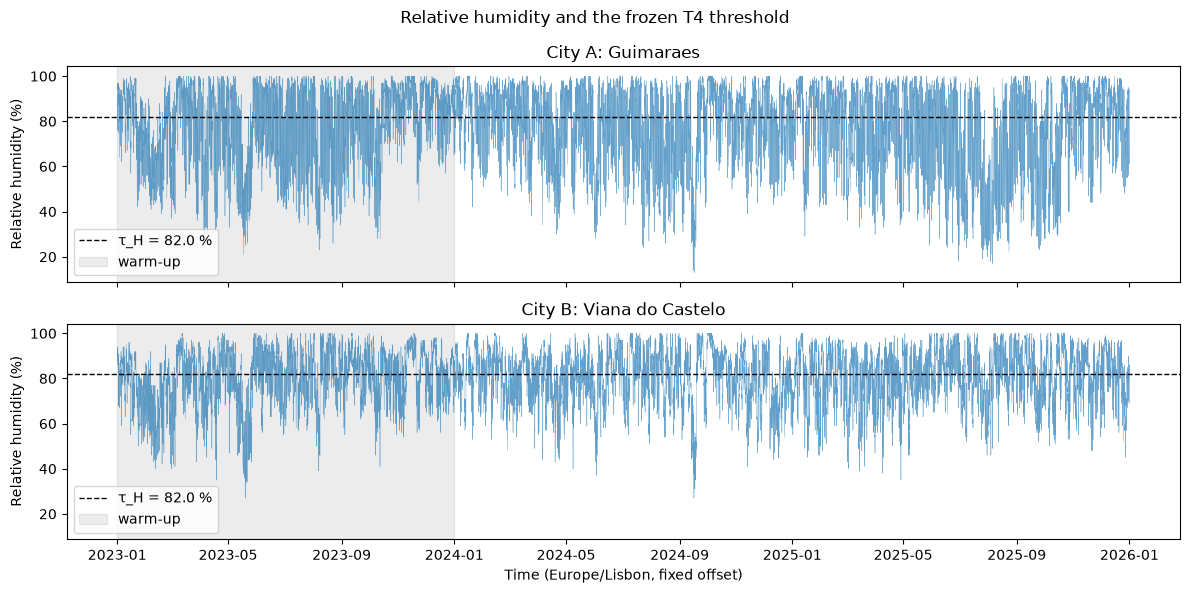

In [15]:
# Figure 01: humidity stream of both cities with the frozen threshold and the warm-up boundary
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (k, df) in zip(axes, frames.items()):
    ax.plot(df["timestamp"], df[TARGET_SOURCE], linewidth=0.3, alpha=0.7)
    ax.axhline(TAU_H, color="black", linestyle="--", linewidth=1, label=f"τ_H = {TAU_H:.1f} %")
    ax.axvspan(WARMUP_START, WARMUP_END, color="grey", alpha=0.15, label="warm-up")
    ax.set_title(f"{ROLE[k]}: {CITIES[k]['name']}")
    ax.set_ylabel("Relative humidity (%)")
    ax.legend(loc="lower left")
axes[-1].set_xlabel(f"Time ({TIMEZONE}, fixed offset)")
fig.suptitle("Relative humidity and the frozen T4 threshold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_humidity_with_threshold.png", dpi=150)
plt.show()

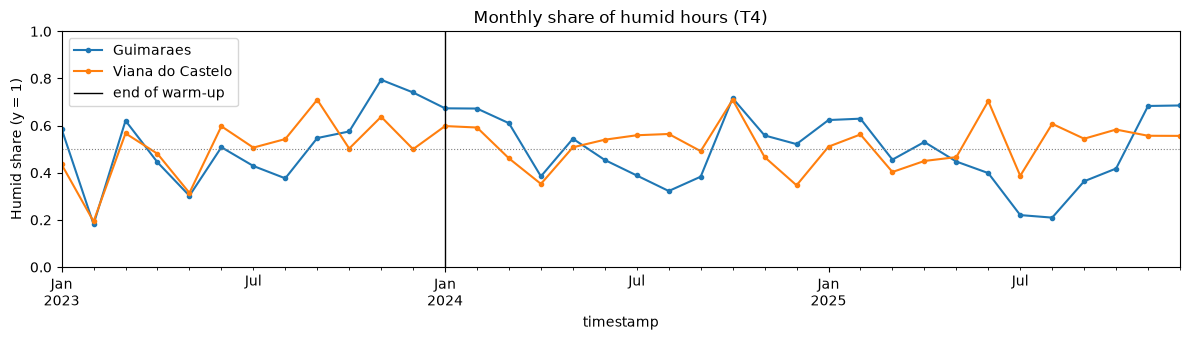

In [16]:
# Figure 02: share of humid hours per month (same threshold for both cities)
monthly = pd.concat(
    {CITIES[k]["name"]: df.set_index("timestamp")["y"].resample("MS").mean() for k, df in frames.items()},
    axis=1,
)
fig, ax = plt.subplots(figsize=(12, 3.5))
monthly.plot(ax=ax, marker="o", markersize=3)
ax.axhline(0.5, color="grey", linewidth=0.8, linestyle=":")
ax.axvline(EVALUATION_START, color="black", linewidth=1, label="end of warm-up")
ax.set_ylabel("Humid share (y = 1)")
ax.set_ylim(0, 1)
ax.set_title("Monthly share of humid hours (T4)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_monthly_humid_share.png", dpi=150)
plt.show()

> 📝 **For the report:** describe the class balance for each city and phase, and what it means for which metrics to trust (Ch. 11.1).

## 11. Protocol checks — temporal-alignment checklist

**Requirement (Ch. 7.1, 12, 20):** these checks turn the handbook's checklist into assertions. If any one fails, the notebook stops.
The checks for features (lags, rolling windows ending at *t−1*) and for PREDICT → EVALUATE → LEARN are done in notebook 04.

In [18]:
checks = {}

# Ch. 12.1: chronological, regular hourly stream
checks["timestamps strictly increasing (both cities)"] = all(
    df["timestamp"].is_monotonic_increasing and df["timestamp"].is_unique for df in frames.values())

# Ch. 3.1 / 12.2: identical timeline and identical warm-up for both cities
checks["identical timestamps in both cities"] = frames[CITY_A]["timestamp"].equals(frames[CITY_B]["timestamp"])
checks["identical warm-up mask in both cities"] = frames[CITY_A]["phase"].equals(frames[CITY_B]["phase"])

# Ch. 6 / 12.3: threshold estimated only from warm-up observations of both cities
checks["tau_H uses only warm-up rows"] = len(pooled_warmup) <= 2 * n_warmup
checks["tau_H reproducible from warm-up data"] = np.isclose(
    pd.concat([df.loc[(df["phase"] == "warm-up") & (df["quality_flag"] == "ok"), TARGET_SOURCE]
               for df in frames.values()]).quantile(TARGET_QUANTILE), TAU_H)
checks["warm-up ends before evaluation starts"] = WARMUP_END < EVALUATION_START

# Ch. 6: target definition matches T4 exactly
checks["y == 1  <=>  H_t >= tau_H"] = all(
    ((df[TARGET_SOURCE] >= TAU_H).astype(float)[df["y"].notna()] == df["y"].dropna()).all()
    for df in frames.values())

# Ch. 18: no undocumented deletion (rows kept = common timeline)
checks["no rows deleted after alignment"] = all(len(df) == len(common_ts) for df in frames.values())

checks_table = pd.Series(checks, name="passed").to_frame()
display(checks_table)
assert checks_table["passed"].all(), "A protocol check failed - fix before continuing."
print("All protocol checks passed.")

,passed
timestamps strictly increasing (both cities),True
identical timestamps in both cities,True
identical warm-up mask in both cities,True
tau_H uses only warm-up rows,True
tau_H reproducible from warm-up data,True
warm-up ends before evaluation starts,True
y == 1 <=> H_t >= tau_H,True
no rows deleted after alignment,True


All protocol checks passed.


## 12. Save processed streams and the frozen configuration

**Requirement (Ch. 15, 15.2):** results must be traceable to code, configuration and data.

Outputs (the input of every later notebook):

| File | Content |
|---|---|
| `data/processed/PA04_<city>_<start>_<end>.csv` | clean chronological stream: timestamps, 4 variables, `quality_flag`, `phase`, `y` |
| `results/config_part1.json` | frozen protocol: τ_H, warm-up boundaries, period, cities, grid points, seed, versions |
| `results/stream_construction_summary.csv` | one table for the report section *Data and Stream Construction* |
| `results/figures/01_*.png`, `02_*.png` | figures from this notebook |

In [19]:
PROCESSED_COLUMNS = ["city", "timestamp", "timestamp_utc", *HOURLY_VARIABLES, "quality_flag", "phase", "y"]
processed_files = {}
for k, df in frames.items():
    out = PROCESSED_DIR / f"{ASSIGNMENT_CODE}_{k}_{START_DATE}_{END_DATE}.csv"
    df[PROCESSED_COLUMNS].to_csv(out, index=False)
    processed_files[k] = str(out.relative_to(ROOT))
    print("Saved", processed_files[k], f"({len(df)} rows)")

Saved data/processed/PA04_guimaraes_2023-01-01_2025-12-31.csv (26304 rows)
Saved data/processed/PA04_viana_do_castelo_2023-01-01_2025-12-31.csv (26304 rows)


In [20]:
frozen_config = {
    "assignment": ASSIGNMENT_CODE,
    "business_scenario": BUSINESS_SCENARIO,
    "business_question": BUSINESS_QUESTION,
    "target": TARGET_CODE,
    "target_name": TARGET_NAME,
    "target_source": TARGET_SOURCE,
    "target_quantile": TARGET_QUANTILE,
    "tau_H": TAU_H,
    "tau_H_n_observations": int(len(pooled_warmup)),
    "cities": {k: {"role": ROLE[k], **c} for k, c in CITIES.items()},
    "grid_points": {k: {f: raw[k].get(f) for f in ("latitude", "longitude", "elevation")} for k in CITIES},
    "period": [START_DATE, END_DATE],
    "hourly_variables": HOURLY_VARIABLES,
    "timezone": TIMEZONE,
    "utc_offset_seconds": {k: raw[k].get("utc_offset_seconds") for k in CITIES},
    "warmup_hours": n_warmup,
    "warmup_start": str(WARMUP_START),
    "warmup_end": str(WARMUP_END),
    "evaluation_start": str(EVALUATION_START),
    "evaluation_end": str(EVALUATION_END),
    "quality_rule": "flag invalid (missing or outside definitional range), keep row, skip incomplete events in replay",
    "valid_ranges": VALID_RANGES,
    "rows_flagged_invalid": {k: int((df["quality_flag"] == "invalid").sum()) for k, df in frames.items()},
    "processed_files": processed_files,
    "random_seed": RANDOM_SEED,
    "versions": VERSIONS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
FROZEN_CONFIG_PATH.write_text(json.dumps(frozen_config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved", FROZEN_CONFIG_PATH.relative_to(ROOT))

Saved results/config_part1.json


In [21]:
# One summary table for the report section "Data and Stream Construction"
summary = pd.DataFrame({
    CITIES[k]["name"]: {
        "role": ROLE[k],
        "grid point (lat, lon)": f"{raw[k]['latitude']:.3f}, {raw[k]['longitude']:.3f}",
        "elevation (m)": raw[k].get("elevation"),
        "period": f"{START_DATE} to {END_DATE}",
        "hours (common timeline)": len(df),
        "rows flagged invalid": int((df["quality_flag"] == "invalid").sum()),
        "warm-up hours": int((df["phase"] == "warm-up").sum()),
        "evaluation hours": int((df["phase"] == "evaluation").sum()),
        "tau_H (pooled, %)": round(TAU_H, 2),
        "humid share, warm-up": round(df.loc[df["phase"] == "warm-up", "y"].mean(), 3),
        "humid share, evaluation": round(df.loc[df["phase"] == "evaluation", "y"].mean(), 3),
    }
    for k, df in frames.items()
})
summary.to_csv(RESULTS_DIR / "stream_construction_summary.csv")
summary

,Guimaraes,Viana do Castelo
role,City A,City B
"grid point (lat, lon)","41.441, -8.288","41.722, -8.857"
elevation (m),170.0,15.0
period,2023-01-01 to 2025-12-31,2023-01-01 to 2025-12-31
hours (common timeline),26304,26304
rows flagged invalid,0,0
warm-up hours,8760,8760
evaluation hours,17544,17544
"tau_H (pooled, %)",82.0,82.0
"humid share, warm-up",0.511,0.5


## Done: what the next notebooks use

Later notebooks start with:

```python
import json, pandas as pd
from utils import ROOT
cfg = json.loads((ROOT / "results" / "config_part1.json").read_text())
TAU_H = cfg["tau_H"]                       # read, never recompute
streams = {k: pd.read_csv(ROOT / f, parse_dates=["timestamp", "timestamp_utc"])
           for k, f in cfg["processed_files"].items()}
```

**Next:**
* **02 / 03 — stream profile (Ch. 9):** temporal evolution, rolling/window behaviour, extremes, persistence of humid/dry regimes, hour-of-day profile, plus at least 2 original analyses (Ch. 3.2), and one business interpretation per city.
* **04 — experiment (Ch. 8, 10–12):** Representation A (t−1) and B (+ delta, rolling mean/std, humid hours in the previous 24 h); GaussianNB, Online LogReg, Hoeffding Tree, Online Bagging, ARF; PREDICT → EVALUATE → LEARN; Accuracy, Macro-F1, Precision/Recall (humid), confusion matrix, predict/update time.